In [1]:
#Importações
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import numpy as np
import sklearn
from ydata_profiling import ProfileReport

from Apoio.config import DADOS_ORIGINAIS, DADOS_SEM_ID

sns.set_theme(palette="bright")

In [2]:
df = pd.read_csv(DADOS_ORIGINAIS)

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.tail()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [5]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [6]:
df.columns = ['id', 'genero', 'idade', 'renda_anual', 'pontuacao_de_gastos_(1-100)']

In [7]:
df.replace({
    'Male': 'Masculino',
    'Female': 'Feminino'
}, inplace=True)

In [8]:
with pd.option_context("display.float_format", "{:.2f}".format):
    display(df.describe())

,id,idade,renda_anual,pontuacao_de_gastos_(1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


In [9]:
df.describe(exclude="number")

,genero
count,200
unique,2
top,Feminino
freq,112


In [10]:
df.isnull().sum()

id                             0
genero                         0
idade                          0
renda_anual                    0
pontuacao_de_gastos_(1-100)    0
dtype: int64

In [11]:
profile = ProfileReport(df)

profile.to_file("../relatorios/eda_supermercado.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 5/5 [00:00<?, ?it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [12]:
df_analise = df.copy()
df_analise = df_analise.drop("id", axis=1)

df_analise.head()

,genero,idade,renda_anual,pontuacao_de_gastos_(1-100)
0,Masculino,19,15,39
1,Masculino,21,15,81
2,Feminino,20,16,6
3,Feminino,23,16,77
4,Feminino,31,17,40


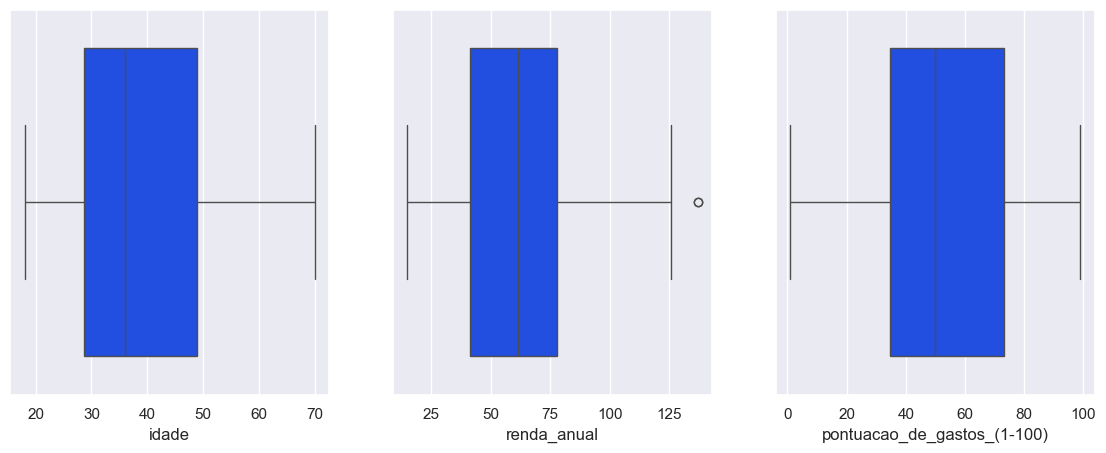

In [13]:
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(14, 5))

for ax, col in zip(axs, df_analise.select_dtypes("number")):
    sns.boxplot(data=df_analise, x=col, ax=ax)
    
plt.show()

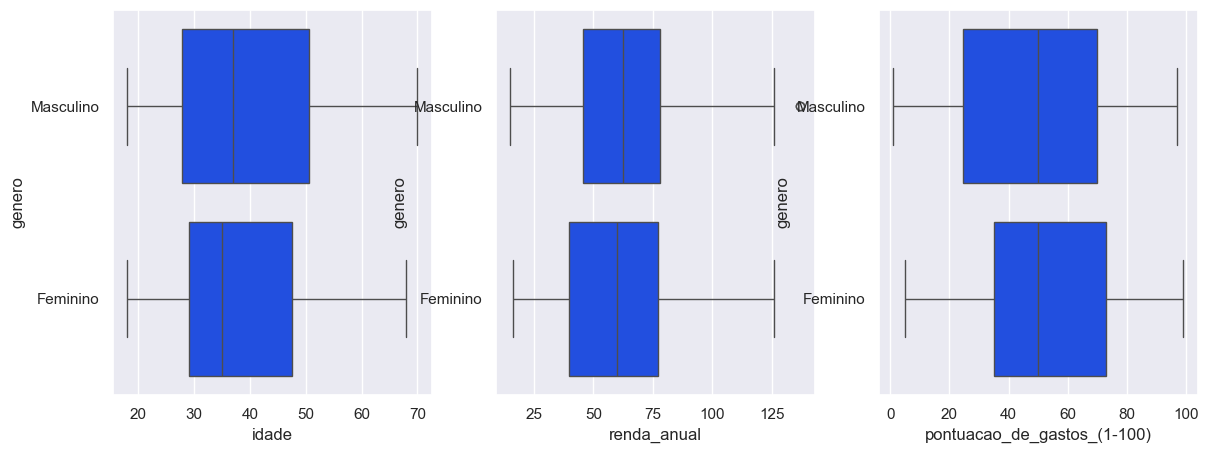

In [14]:
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(14, 5))

for ax, col in zip(axs, df_analise.select_dtypes("number")):
    sns.boxplot(data=df_analise, x=col, y="genero", ax=ax)
    
plt.show()

In [15]:
with pd.option_context("display.float_format", "{:.2f}".format):
    display(df_analise.corr(numeric_only=True))

,idade,renda_anual,pontuacao_de_gastos_(1-100)
idade,1.00,-0.01,-0.33
renda_anual,-0.01,1.00,0.01
pontuacao_de_gastos_(1-100),-0.33,0.01,1.00


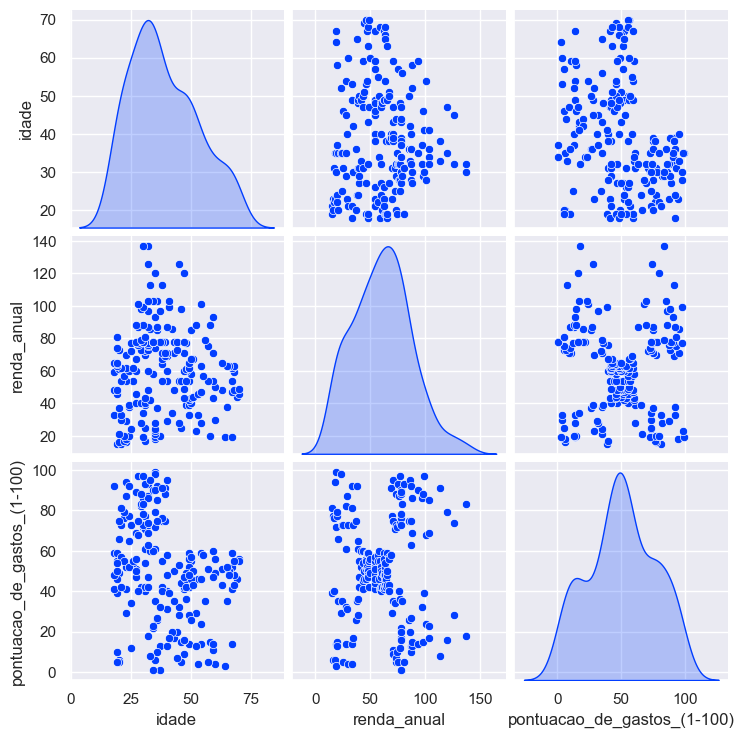

In [16]:
sns.pairplot(df_analise, diag_kind="kde");

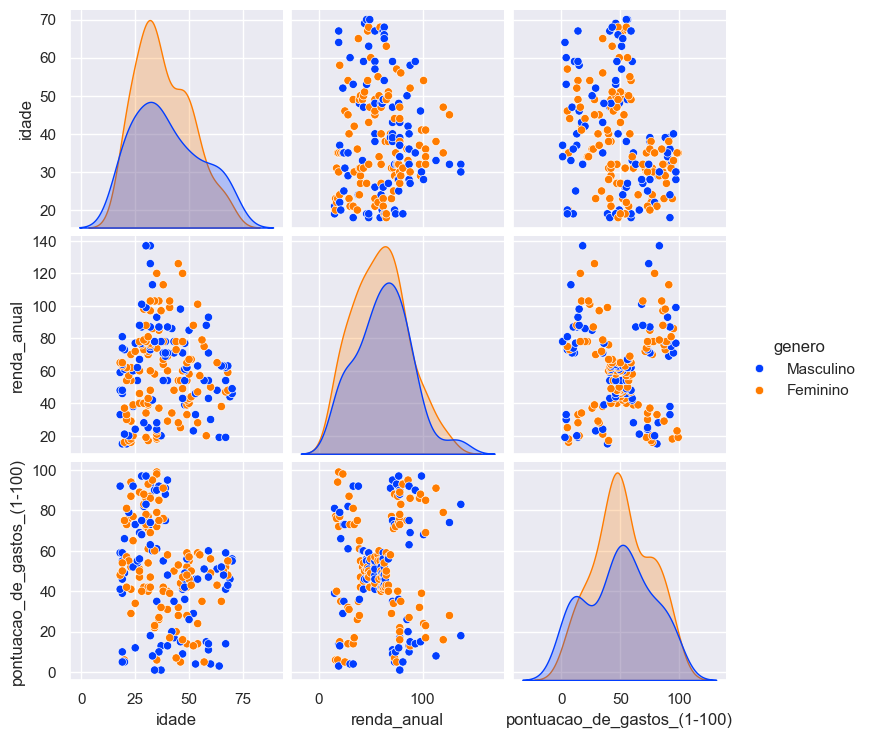

In [17]:
sns.pairplot(df_analise, diag_kind="kde", hue="genero");

In [18]:
df_analise.to_csv(DADOS_SEM_ID, index=False)